<h1>Cek Dataset</h1>

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

In [2]:
df = pd.read_csv("data_uji.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   No        200 non-null    int64  
 1   Aplikasi  200 non-null    str    
 2   Rating    200 non-null    float64
 3   Type      200 non-null    str    
 4   Data ke   200 non-null    int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 7.9 KB


Deskripsi rating

In [3]:
df["Rating"].describe()

count    200.000000
mean       4.222000
std        0.493593
min        1.700000
25%        4.000000
50%        4.300000
75%        4.600000
max        5.000000
Name: Rating, dtype: float64

In [4]:
ringkasan = df.groupby("Type")["Rating"].agg(["count", "mean", "std"])
ringkasan

,count,mean,std
Type,,,
Free,100,4.248,0.40113
Paid,100,4.196,0.57224


<h1>Analisis Data</h1>
Histogram

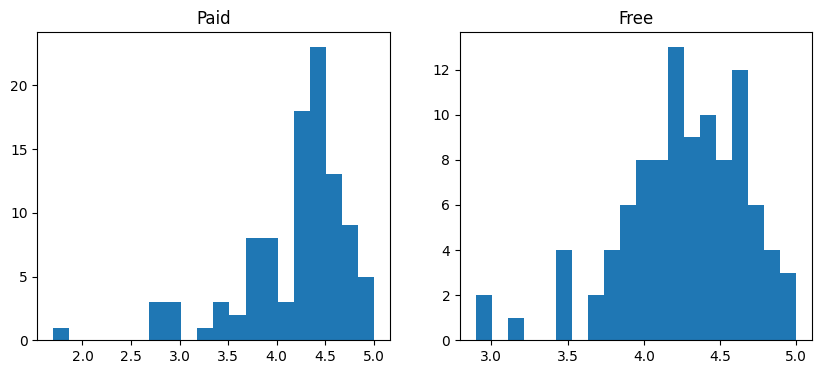

In [5]:
import matplotlib.pyplot as plt

paid = df[df["Type"] == "Paid"]["Rating"]
free = df[df["Type"] == "Free"]["Rating"]

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
ax[0].hist(paid, bins=20); ax[0].set_title("Paid")
ax[1].hist(free, bins=20); ax[1].set_title("Free")
plt.show()

<h3>Skewness (Kemiringan)</h3>
Skewness mengukur ketidaksimetrisan distribusi data

In [6]:
print("Skewness Paid:", stats.skew(paid))
print("Skewness Free:", stats.skew(free))

Skewness Paid: -1.5836379624072003
Skewness Free: -0.8051395715653858


Hasilnya _negative skew_, hampir semua aplikasi memiliki rating 3.5 - 5

<h3>Uji-t Welch</h3>
Uji-t Welch digunakan untuk membandingkan rata-rata dari 2 kelompok data yang saling bebas dan karena ketimpangan jumlah data antar kelompok.

In [7]:
hasil = stats.ttest_ind(paid, free, equal_var=False)

print("t        :", hasil.statistic)
print("df       :", hasil.df)
print("p-value  :", hasil.pvalue)

t        : -0.7441006505229548
df       : 177.36991439375012
p-value  : 0.4578002221815018


berdasarkan nilai t, rata-rata rating Paid app lebih rendah dari Free app. 
berdasarkan p-value, diatas nilai alpha, maka perbedaan rata-rata tidak signifikan

<h3>Interval Kepercayaan 95%</h3>
Menghitung rentang nilai rata-rata yang mewakili populasi sebenarnya

In [8]:
mean_free = free.mean()
mean_paid = paid.mean()
selisih = mean_paid - mean_free

print("Selisih rata-rata : ", selisih)
ci = hasil.confidence_interval(confidence_level=0.95)
print("CI 95%:", ci.low, "sampai", ci.high)

Selisih rata-rata :  -0.051999999999998714
CI 95%: -0.18990916758076923 sampai 0.0859091675807718


selisih rata-rata yang diambil dri sampel adalah -0.052, sehingga dengan kepercayaan 95%, selisih rata-rata rating sebenarnya adalah antara -0.19 dan 0.09

<h3>Cohen's d</h3>
Mengukur seberdampak apa perbedaan rata-rata antara app gratis dan berbayar

In [9]:
n1, n2 = len(paid), len(free)
s1, s2 = paid.std(), free.std()
sp = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
d = (paid.mean() - free.mean()) / sp
print("Cohen's d:", d)

Cohen's d: -0.10523172317402053


hasil d menunjukkan bahwa tidak ada efeknya rating terhadap harga aplikasi

<h3>Keputusan</h3>

In [10]:
alpha = 0.05
print(hasil.pvalue)
if hasil.pvalue < alpha:
    print("Tolak H0")
else:
    print("Gagal tolak H0")

0.4578002221815018
Gagal tolak H0


hasil statistik tidak membenarkan asumsi developer. Aplikasi gratis maupun berbayar tidak memengaruhi ketinggian rating. Semua tergantung pilihan dan kebutuhan pengguna.